# Prebuilt robots

ARIEL ships a set of ready-made robot bodies: 13 from John's set (baby, a small gecko, snake, turtle, iguana, three spiders, three centipedes and more), plus the gecko and a plain spider. Each is a function that returns a `CoreModule`, the root of a tree of body parts.

In this notebook you build all 15, drop each one into a flat world, compare their size in a table and a chart, let each fall and settle for one second with no control, and check that nothing blows up. A sketch of every robot is drawn from the model's geoms, so it needs no graphics card. If this machine has a working OpenGL backend the last section also renders every robot; without one it says so and the rest still runs.

`ariel.rendering` comes first. Importing it chooses the OpenGL backend, and MuJoCo reads that choice when it loads, so no cell before this one may import `mujoco`.

In [1]:
from typing import cast

from ariel.rendering import (  # chooses the OpenGL backend before MuJoCo loads
    single_frame_renderer,
)

One-off setup: testing which OpenGL backends work on this machine. The result is saved to mujoco_user_config.json; 
this will not be repeated.

Output()

In [2]:
# Standard library
from pathlib import Path

In [3]:
# Third-party libraries
import matplotlib.pyplot as plt
import mujoco
import numpy as np
from matplotlib.collections import PolyCollection
from rich.table import Table

In [4]:
# Local libraries
from ariel import console
from ariel.body_phenotypes.robogen_lite.prebuilt_robots import (
    gecko,
    john_set,
    spider,
)
from ariel.simulation import SimpleFlatWorld

In [5]:
# Settings (nothing here is random)
ROBOTS = 15  # 13 from John's set plus the gecko and the spider
SETTLE_STEPS = 400
RENDER_SIZE = 240
DATA = Path.cwd() / "__data__" / "prebuilt_robots"
DATA.mkdir(parents=True, exist_ok=True)

## Build every robot

A builder takes no arguments and returns a new `CoreModule` each time. `spec` holds the MuJoCo description of the whole body.

In [6]:
builders = {
    name: getattr(john_set, name)
    for name in (
        "baby_a",
        "baby_b",
        "gecko_small",
        "linkin_modified",
        "snake",
        "turtle",
        "iguana",
        "spider_8",
        "spider_12",
        "spider_16",
        "centipede_3",
        "centipede_4",
        "centipede_5",
    )
}
builders["gecko"] = gecko.gecko
builders["spider"] = spider.spider
console.print(f"{len(builders)} robots")
assert len(builders) == ROBOTS

15 robots

## Drop each one into a flat world

`SimpleFlatWorld.spawn` adds the body to the world. After compiling, the model tells us how many bodies, geoms and actuators the robot has and how much it weighs. Then we step the physics for a short time with no control and keep the data.

In [7]:
models = {}
settled = {}
for name, build in builders.items():
    world = SimpleFlatWorld(load_precompiled=False)
    world.spawn(build().spec)
    model = cast("mujoco.MjModel", world.spec.compile())
    data = mujoco.MjData(model)
    for _ in range(SETTLE_STEPS):
        mujoco.mj_step(model, data)
    models[name] = model
    settled[name] = data

In [8]:
table = Table(title="Prebuilt robots")
for column in (
    "robot",
    "bodies",
    "geoms",
    "actuators",
    "mass (kg)",
    "core height (m)",
):
    table.add_column(column, justify="right" if column != "robot" else "left")
for name, model in models.items():
    table.add_row(
        name,
        str(model.nbody),
        str(model.ngeom),
        str(model.nu),
        f"{model.body_mass.sum():.2f}",
        f"{settled[name].qpos[2]:.3f}",
    )
console.print(table)

                               Prebuilt robots                                
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ robot           ┃ bodies ┃ geoms ┃ actuators ┃ mass (kg) ┃ core height (m) ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ baby_a          │     35 │    25 │         8 │      2.59 │           0.075 │
│ baby_b          │     44 │    32 │        10 │      2.97 │           0.075 │
│ gecko_small     │     28 │    20 │         6 │      2.33 │           0.075 │
│ linkin_modified │     43 │    29 │        12 │      2.77 │           0.075 │
│ snake           │     35 │    25 │         8 │      2.63 │           0.075 │
│ turtle          │     49 │    34 │        13 │      3.07 │           0.075 │
│ iguana          │     34 │    24 │         8 │      2.53 │           0.075 │
│ spider_8        │     36 │    26 │         8 │      2.65 │           0.075 │
│ spider_12       │     52 │    38 │        12 │      3.29 │           0.075 │
│ spider_16       │     68 │    50 │        16 │      3.93 │           0.075 │
│ centipede_3     │     48 │    35 │        11 │      3.14 │           0.075 │
│ centipede_4     │     60 │    44 │        14 │      3.62 │           0.075 │
│ centipede_5     │     72 │    53 │        17 │      4.12 │           0.075 │
│ gecko           │     34 │    24 │         8 │      2.53 │           0.075 │
│ spider          │     32 │    22 │         8 │      2.40 │           0.075 │
└─────────────────┴────────┴───────┴───────────┴───────────┴─────────────────┘

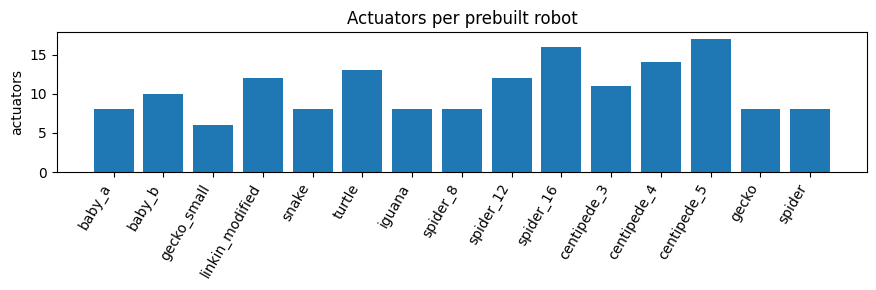

In [9]:
fig, axis = plt.subplots(figsize=(9, 3))
axis.bar(list(models), [m.nu for m in models.values()])
axis.set_ylabel("actuators")
axis.set_title("Actuators per prebuilt robot")
plt.setp(axis.get_xticklabels(), rotation=60, ha="right")
plt.tight_layout()
plt.show()

## Checks

Every robot must have actuators and mass, and after settling its state must be finite (no NaN) with the core above the floor. The spiders and centipedes come in sizes, so their actuator counts must grow with the size in the name.

In [10]:
for name, model in models.items():
    assert model.nu > 0, name
    assert model.body_mass.sum() > 0, name
    assert np.isfinite(settled[name].qpos).all(), name
    assert settled[name].qpos[2] > 0, name  # core above the floor
spiders = [models[n].nu for n in ("spider_8", "spider_12", "spider_16")]
centipedes = [
    models[n].nu for n in ("centipede_3", "centipede_4", "centipede_5")
]
assert spiders == sorted(spiders)
assert centipedes == sorted(centipedes)

## Look at them without OpenGL

A picture needs no graphics card if we draw it ourselves. Every geom of the compiled model has a position, a rotation and a size, so the loop below draws each geom as the six faces of its bounding box (a sphere or capsule becomes the box around it), seen from above and from the side, in the colour the model gives it. It is a sketch, not a render, but it shows the shape of every robot from one loop.

In [11]:
CORNERS = np.array([
    [x, y, z] for x in (-1, 1) for y in (-1, 1) for z in (-1, 1)
])
FACES = [
    [0, 1, 3, 2],
    [4, 5, 7, 6],
    [0, 1, 5, 4],
    [2, 3, 7, 6],
    [0, 2, 6, 4],
    [1, 3, 7, 5],
]
TYPE = mujoco.mjtGeom


def half_extent(
    model: mujoco.MjModel, geom: int
) -> tuple[np.ndarray, np.ndarray]:
    size = model.geom_size[geom]
    kind = model.geom_type[geom]
    centre = np.zeros(3)
    if kind == TYPE.mjGEOM_SPHERE:
        half = np.full(3, size[0])
    elif kind == TYPE.mjGEOM_CAPSULE:
        half = np.array([size[0], size[0], size[1] + size[0]])
    elif kind == TYPE.mjGEOM_CYLINDER:
        half = np.array([size[0], size[0], size[1]])
    elif kind == TYPE.mjGEOM_MESH:
        centre, half = model.geom_aabb[geom][:3], model.geom_aabb[geom][3:]
    else:  # box, ellipsoid
        half = size
    return centre, half


def sketch(
    model: mujoco.MjModel, data: mujoco.MjData, axis: plt.Axes, across: int
) -> None:
    # across: the world axis drawn upward (1 top view, 2 side view)
    faces, colours = [], []
    for geom in range(model.ngeom):
        if model.geom_type[geom] == TYPE.mjGEOM_PLANE:
            continue  # the floor
        centre, half = half_extent(model, geom)
        rotation = data.geom_xmat[geom].reshape(3, 3)
        corners = data.geom_xpos[geom] + (centre + CORNERS * half) @ rotation.T
        flat = corners[:, [0, across]]
        faces += [flat[face] for face in FACES]
        colours += [model.geom_rgba[geom]] * len(FACES)
    solid = PolyCollection(
        faces, facecolors=colours, edgecolors="k", linewidths=0.2
    )
    axis.add_collection(solid)
    axis.autoscale()
    axis.set_aspect("equal")
    axis.axis("off")

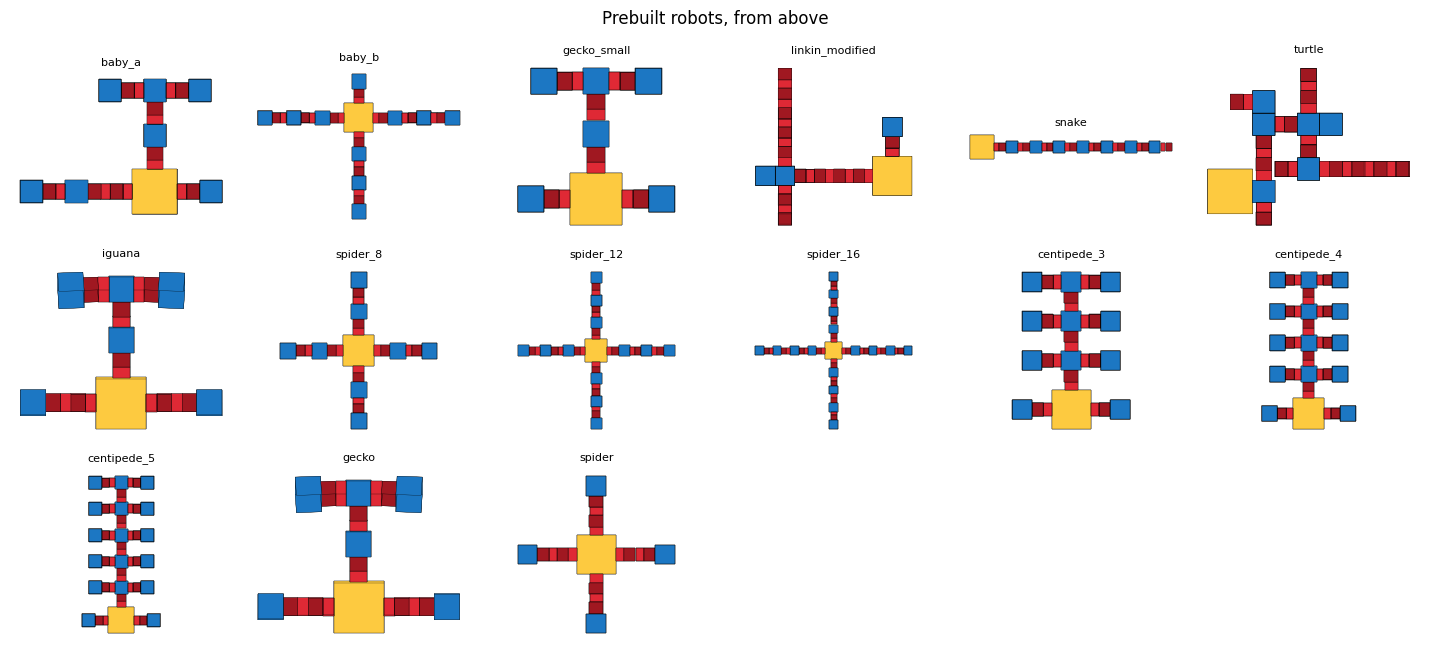

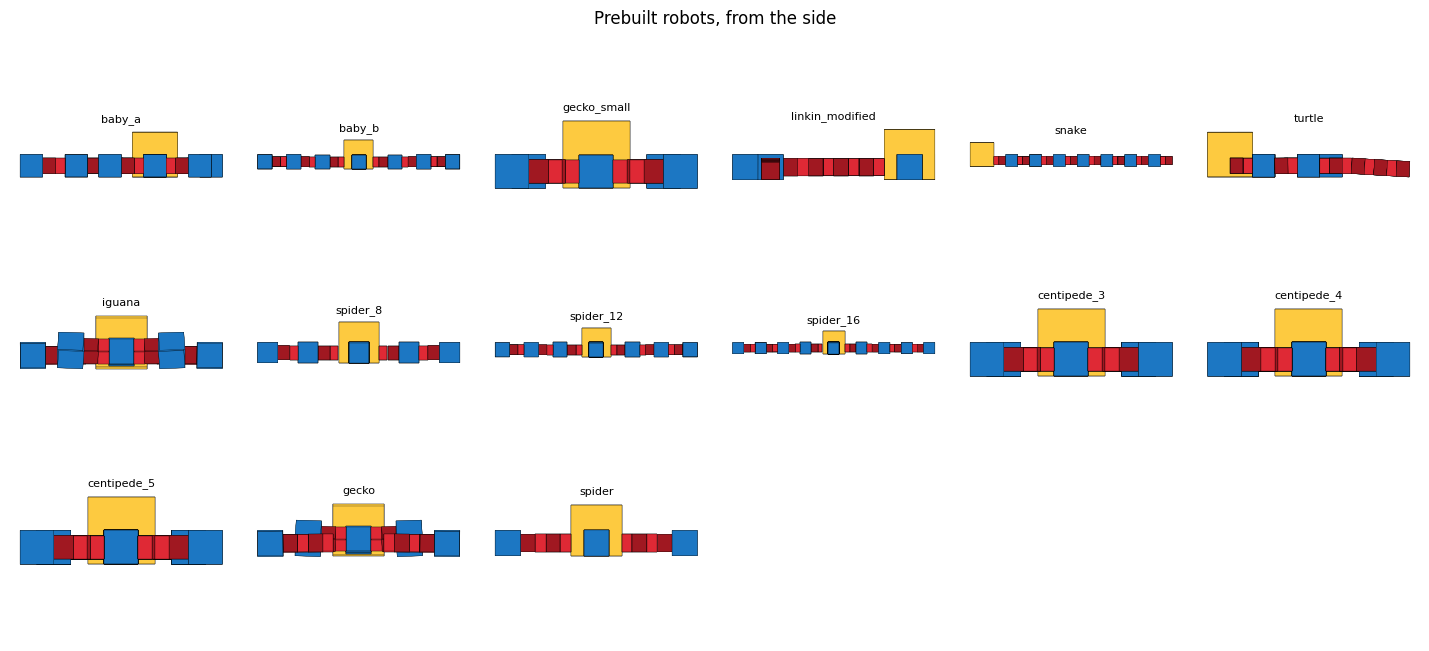

In [12]:
columns = 6
rows = -(-len(models) // columns)
for across, view in ((1, "from above"), (2, "from the side")):
    fig, axes = plt.subplots(rows, columns, figsize=(2.4 * columns, 2.2 * rows))
    for axis in axes.flat:
        axis.axis("off")
    for axis, (name, model) in zip(axes.flat, models.items(), strict=False):
        mujoco.mj_forward(model, settled[name])
        sketch(model, settled[name], axis, across)
        axis.set_title(name, fontsize=8)
    fig.suptitle(f"Prebuilt robots, {view}")
    plt.tight_layout()
    plt.show()

## Look at them (needs OpenGL)

Rendering needs a working OpenGL backend. The first cell tries to open a tiny render context. If it fails, the next cell prints a message instead of pictures. Otherwise `single_frame_renderer` settles each robot again and renders it.

In [13]:
try:
    mujoco.Renderer(mujoco.MjModel.from_xml_string("<mujoco/>"), 8, 8).close()
    OPENGL = True
except mujoco.FatalError:
    OPENGL = False
console.print(f"OpenGL works: {OPENGL}")

OpenGL works: True

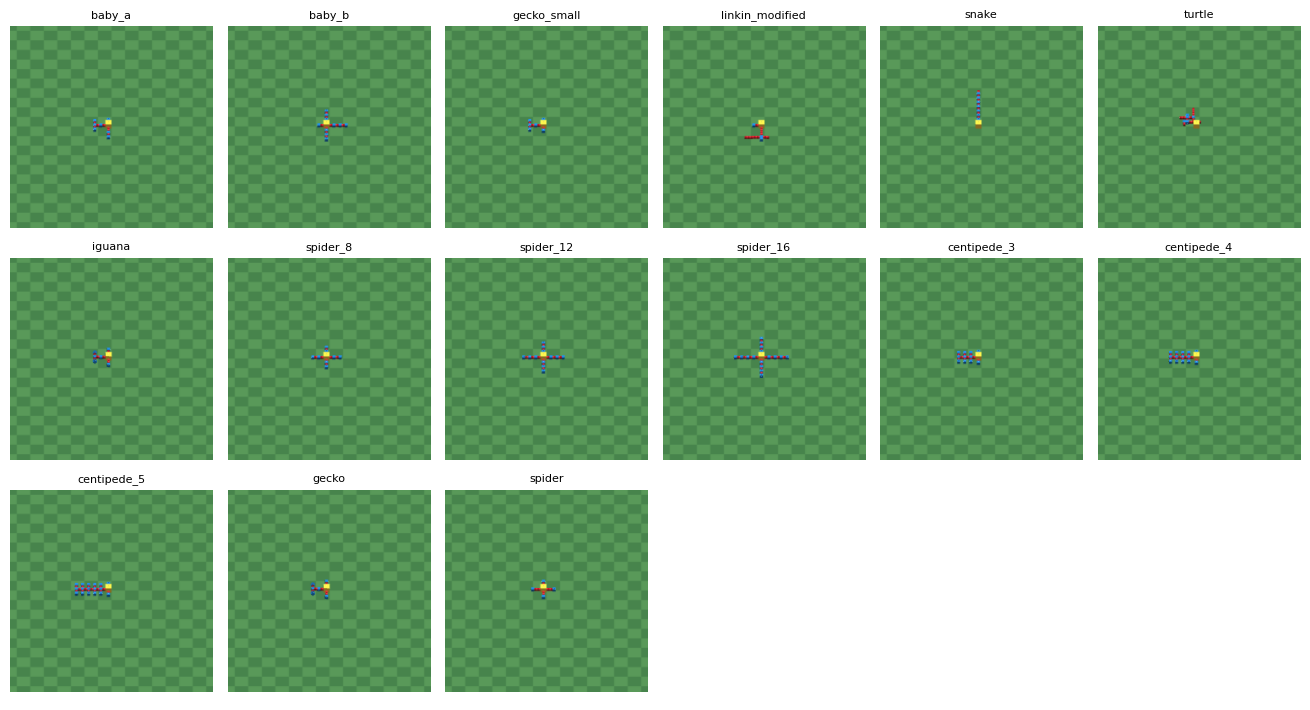

In [14]:
if OPENGL:
    columns = 6
    rows = -(-len(models) // columns)
    size = (2.2 * columns, 2.4 * rows)
    fig, axes = plt.subplots(rows, columns, figsize=size)
    for axis in axes.flat:
        axis.axis("off")
    for axis, (name, model) in zip(axes.flat, models.items(), strict=False):
        picture = single_frame_renderer(
            model,
            settled[name],
            steps=SETTLE_STEPS,
            width=RENDER_SIZE,
            height=RENDER_SIZE,
        )
        assert np.asarray(picture).std() > 0, name  # not one flat colour
        axis.imshow(picture)
        axis.set_title(name, fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    console.print("No working OpenGL backend: skipped the pictures.")